# Task 1 - Undersampling (adult census income)
AI use: Claude was used to guide the structure and understand some concepts that were quite confusing. I ran the code myself and checked the outputs.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from imblearn.under_sampling import RandomUnderSampler


In [ ]:
df = pd.read_csv("../../../Datasets/adult.csv")   

df = df.drop_duplicates()
df = df.replace("?", np.nan).dropna()
df.shape

(30139, 15)

#### Step 1a – Selected column: `income`
I chose `income` because it is clearly imbalanced: about 75% of rows are `<=50K` and only 25% are `>50K`.

#### Step 1b, histogram 

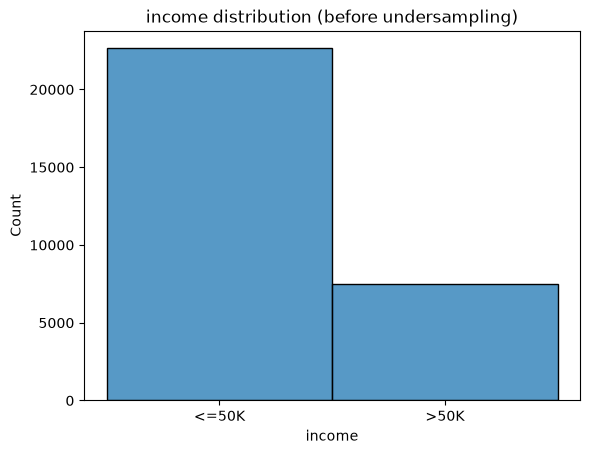

In [3]:
sns.histplot(df, x="income")
plt.title("income distribution (before undersampling)")
plt.show()

In [5]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

#### Step 1c, rows and statistics before

In [6]:
print("Rows before:", len(df))
print(df["income"].value_counts())
df.describe()

Rows before: 30139
income
<=50K    22633
>50K      7506
Name: count, dtype: int64


,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,30139.00,30139.00,30139.00,30139.00,30139.00,30139.00
mean,38.44,189795.03,10.12,1092.84,88.44,40.93
std,13.13,105658.62,2.55,7409.11,404.45,11.98
min,17.00,13769.00,1.00,0.00,0.00,1.00
25%,28.00,117627.50,9.00,0.00,0.00,40.00
50%,37.00,178417.00,10.00,0.00,0.00,40.00
75%,47.00,237604.50,13.00,0.00,0.00,45.00
max,90.00,1484705.00,16.00,99999.00,4356.00,99.00


In [7]:
df.var(numeric_only=True)

age                      172.43
fnlwgt           11163744897.54
education.num              6.50
capital.gain        54894919.83
capital.loss          163575.95
hours.per.week           143.49
dtype: float64

#### Step 1d, undersample

In [8]:
# split first, so the target does not leak into the features
X = df.drop(columns="income")
y = df["income"]

sampler = RandomUnderSampler(random_state=321)
X_resampled, y_resampled = sampler.fit_resample(X, y)

# rebuild one DataFrame with the target added back
df_resampled = X_resampled.copy()
df_resampled["income"] = y_resampled

#### Step 1e, histogram after

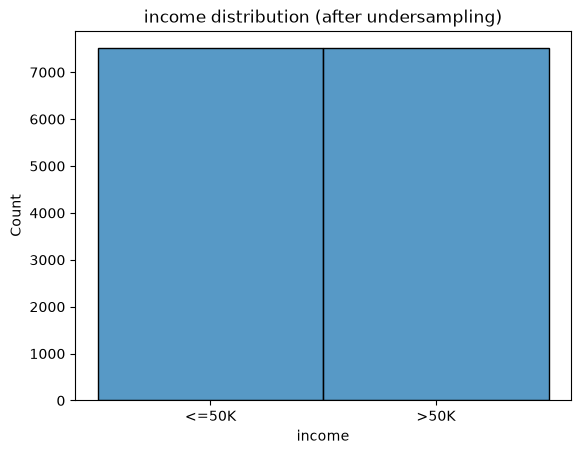

In [9]:
sns.histplot(df_resampled, x="income")
plt.title("income distribution (after undersampling)")
plt.show()

#### Step 1f, rows and statistics after

In [10]:
print("Rows after:", len(df_resampled))
print(df_resampled["income"].value_counts())
df_resampled.describe()

Rows after: 15012
income
<=50K    7506
>50K     7506
Name: count, dtype: int64


,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,15012.00,15012.00,15012.00,15012.00,15012.00,15012.00
mean,40.30,189618.63,10.62,2045.00,123.09,42.52
std,12.53,104519.06,2.58,10372.69,477.87,11.93
min,17.00,13769.00,1.00,0.00,0.00,1.00
25%,31.00,118307.50,9.00,0.00,0.00,40.00
50%,40.00,177944.00,10.00,0.00,0.00,40.00
75%,49.00,236043.75,13.00,0.00,0.00,50.00
max,90.00,1455435.00,16.00,99999.00,4356.00,99.00


In [11]:
df_resampled.var(numeric_only=True)

age                      156.89
fnlwgt           10924234794.41
education.num              6.68
capital.gain       107592754.48
capital.loss          228361.41
hours.per.week           142.39
dtype: float64

#### Extra step

In [13]:
X = df.drop(columns="income")
y = df["income"]


strategy = {
    "<=50K": 15000,
    ">50K": 7506
}

sampler = RandomUnderSampler(sampling_strategy=strategy, random_state=321)
X_resampled, y_resampled = sampler.fit_resample(X, y)

df_resampled = X_resampled.copy()
df_resampled["income"] = y_resampled

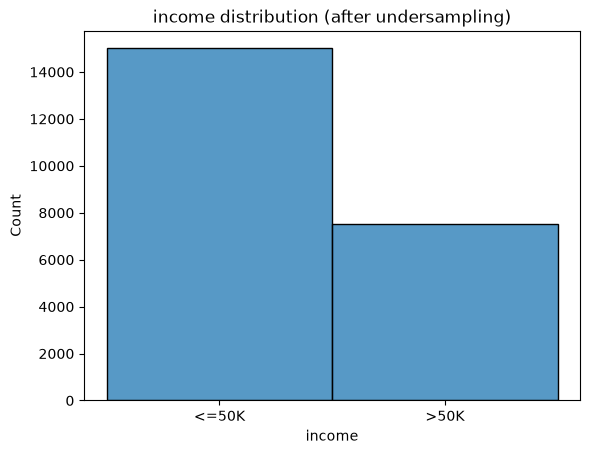

In [14]:
sns.histplot(df_resampled, x="income")
plt.title("income distribution (after undersampling)")
plt.show()

In [15]:
print("Rows after:", len(df_resampled))
print(df_resampled["income"].value_counts())
df_resampled.describe()

Rows after: 22506
income
<=50K    15000
>50K      7506
Name: count, dtype: int64


,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,22506.00,22506.00,22506.00,22506.00,22506.00,22506.00
mean,39.11,189857.85,10.29,1416.34,98.73,41.47
std,12.96,105649.10,2.58,8536.59,428.10,11.96
min,17.00,13769.00,1.00,0.00,0.00,1.00
25%,29.00,117792.75,9.00,0.00,0.00,40.00
50%,38.00,178727.00,10.00,0.00,0.00,40.00
75%,48.00,236696.00,13.00,0.00,0.00,45.00
max,90.00,1455435.00,16.00,99999.00,4356.00,99.00


In [16]:
df_resampled.var(numeric_only=True)

age                      168.08
fnlwgt           11161732428.59
education.num              6.64
capital.gain        72873369.91
capital.loss          183269.39
hours.per.week           143.03
dtype: float64

In [17]:
sampler_even = RandomUnderSampler(random_state=321)
X_even, y_even = sampler_even.fit_resample(X, y)
df_resampled_even = X_even.copy()
df_resampled_even["income"] = y_even

In [18]:
comparison = pd.DataFrame({
    "original": df.mean(numeric_only=True),
    "partial (2:1)": df_resampled.mean(numeric_only=True),
    "even (1:1)": df_resampled_even.mean(numeric_only=True),
}).round(1)
comparison

,original,partial (2:1),even (1:1)
age,38.40,39.10,40.30
fnlwgt,189795.00,189857.90,189618.60
education.num,10.10,10.30,10.60
capital.gain,1092.80,1416.30,2045.00
capital.loss,88.40,98.70,123.10
hours.per.week,40.90,41.50,42.50


### Conclusion

* I tried two undersampling stratagies with RandomUnderSampler. The even strategy (7506/7506) balanced the target perfectly but removed half of the dataset. The partial strategy (15000/7506) kept 75% of the rows and made >50k 33% of the data instead of 25%.

* Both changed the statastics of the features that are related to income, because the removed rows were mostly <=50k people (younger, fewer hours, less capital gain). For example, the mean capital.gain went from 1092 to 1416 in partial strategy and to 2045 with the even startegy. The unrelated column fnlwgt stayed almost the same in both. 

* I would say neither version reflects the real distribution, where only 25% earn >50k. I would choose the partial strategy when keeping data and realism matters, and the even strategy when model training needs a balanceed target and there is enough data to lose half of it. Undersampling works on large datasets, where removing rows still leaves enough to learn from.